# Power spectra

Compute the power spectra for real data of either a scalar or vector field as a Fourier transform in the zonal direction (averaged in time, vertical or meridional dimensions as required).

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
from scores.dynamics import power_spectra_scalar, power_spectra_vector, energy_components_lat_lon
import matplotlib.pyplot as plt

Copy down the January 2020 data for ERA5 on a 240x121 grid.

In [2]:
START_TIME = pd.Timestamp("2020-01-01")
END_TIME = pd.Timestamp("2020-01-09")
ds = xr.open_zarr("gs://weatherbench2/datasets/era5/1959-2023_01_10-6h-240x121_equiangular_with_poles_conservative.zarr")
ds = ds.sel(time=slice(START_TIME, END_TIME))

Prepare the data, selecting the desired fields (velocity components for kinetic energy, and any others of interest), and ordering dimensions as required.

In [3]:
fieldnames = ['u_component_of_wind','v_component_of_wind','temperature']
ds = ds[fieldnames]
ds = ds.compute()
ds = ds.rename({'u_component_of_wind': 'u', 'v_component_of_wind': 'v', 'temperature': 't'})

Copy down the January 2020 data for GraphCast on a 240x121 grid for comparison.

In [4]:
ds_gc = xr.open_zarr("gs://weatherbench2/datasets/graphcast/2020/date_range_2019-11-16_2021-02-01_12_hours-240x121_equiangular_with_poles_conservative.zarr")
lead_time = pd.Timedelta("2d")
ds_gc = ds_gc.sel(time=slice(START_TIME, END_TIME), prediction_timedelta=lead_time, method="nearest")

In [5]:
ds_gc = ds_gc[fieldnames]
ds_gc = ds_gc.compute()
ds_gc = ds_gc.rename({'u_component_of_wind': 'u', 'v_component_of_wind': 'v', 'temperature': 't'})

Compute the zonal Fourier transform of the kinetic energy, $K = (u^2 + v^2)/2$ as the default, averaging over the vertical and temporal dimensions

In [6]:
Khat = power_spectra_vector(ds, reduce_vertical=True, reduce_time=False)
Khat_gc = power_spectra_vector(ds_gc, reduce_vertical=True, reduce_time=False)

Plot the power spectra for the zonal kinetic energy as a function of spatial frequency at the equator, averaged over the vertical and temporal dimensions, and compare this to the $k^{-3}$ theoretical rate of energy transfer for two dimensional turbulence.

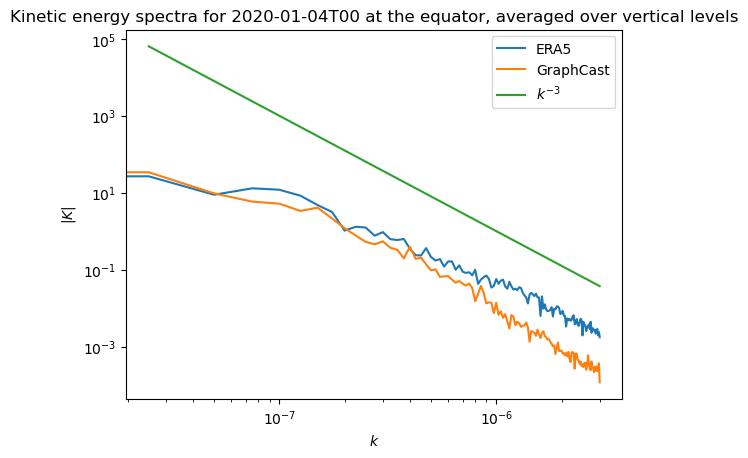

In [7]:
date = '2020-01-04T00'
latitude = 0
freq = Khat['frequency'].sel(latitude=latitude).to_numpy()
amp_sq = Khat['amplitude_squared'].sel(time=date, latitude=latitude).to_numpy()
freq_gc = Khat_gc['frequency'].sel(latitude=latitude).to_numpy()
amp_sq_gc = Khat_gc['amplitude_squared'].sel(time=date, latitude=latitude).to_numpy()
plt.loglog(freq,amp_sq)
plt.loglog(freq_gc,amp_sq_gc)
plt.plot(freq[1:],1.0e-18*np.power(freq[1:],-3.))
plt.ylabel(r'$|K|$')
plt.xlabel(r'$k$')
plt.legend(['ERA5', 'GraphCast', r'$k^{-3}$'])
plt.title('Kinetic energy spectra for ' + date + ' at the equator, averaged over vertical levels')
plt.show()

This time, preserve the vertical and temporal dimensions

In [8]:
Khat = power_spectra_vector(ds, reduce_vertical=False, reduce_time=False)
Khat_gc = power_spectra_vector(ds_gc, reduce_vertical=False, reduce_time=False)

...and average over the equatorial latitudes and plot the spectra for the first time at 850 hPa.

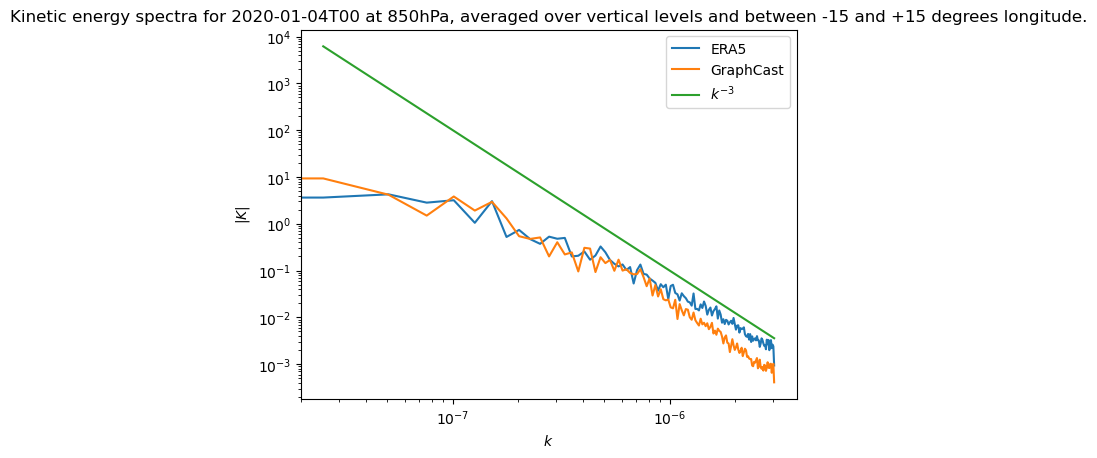

In [9]:
level = 850
lats = Khat.latitude[(Khat.latitude >= -15.0) & (Khat.latitude <= +15.0)]
Khat_eq = Khat.sel(latitude=lats,time=date,level=level)
Khat_eq_avg = Khat_eq.mean(dim='latitude')
Khat_gc_eq = Khat_gc.sel(latitude=lats,time=date,level=level)
Khat_gc_eq_avg = Khat_gc_eq.mean(dim='latitude')
freq = Khat_eq_avg['frequency'].to_numpy()
freq_gc = Khat_gc_eq_avg['frequency'].to_numpy()
amp_sq = Khat_eq_avg['amplitude_squared'].to_numpy()
amp_sq_gc = Khat_gc_eq_avg['amplitude_squared'].to_numpy()
plt.loglog(freq,amp_sq)
plt.loglog(freq_gc,amp_sq_gc)
plt.plot(freq[1:],1.0e-19*np.power(freq[1:],-3.))
plt.legend(['ERA5', 'GraphCast', r'$k^{-3}$'])
plt.ylabel(r'$|K|$')
plt.xlabel(r'$k$')
plt.title('Kinetic energy spectra for ' + date + ' at ' + str(level) + \
          'hPa, averaged over vertical levels and between -15 and +15 degrees longitude.')
plt.show()

We can also compute the spectra for a subdomain in both latitude and longitude, for which a cosine bell filter (Tukey window) is applied in the zonal direction.

In [10]:
lons = ds.longitude[(ds.longitude < +180.0)]
lats = ds.latitude[(ds.latitude >= -15.0) & (ds.latitude <= +15.0)]
ds_subdomain = ds.sel(latitude=lats, longitude=lons)
ds_gc_subdomain = ds_gc.sel(latitude=lats, longitude=lons)
Khat = power_spectra_vector(ds_subdomain, reduce_vertical=False, reduce_time=False)
Khat_gc = power_spectra_vector(ds_gc_subdomain, reduce_vertical=False, reduce_time=False)

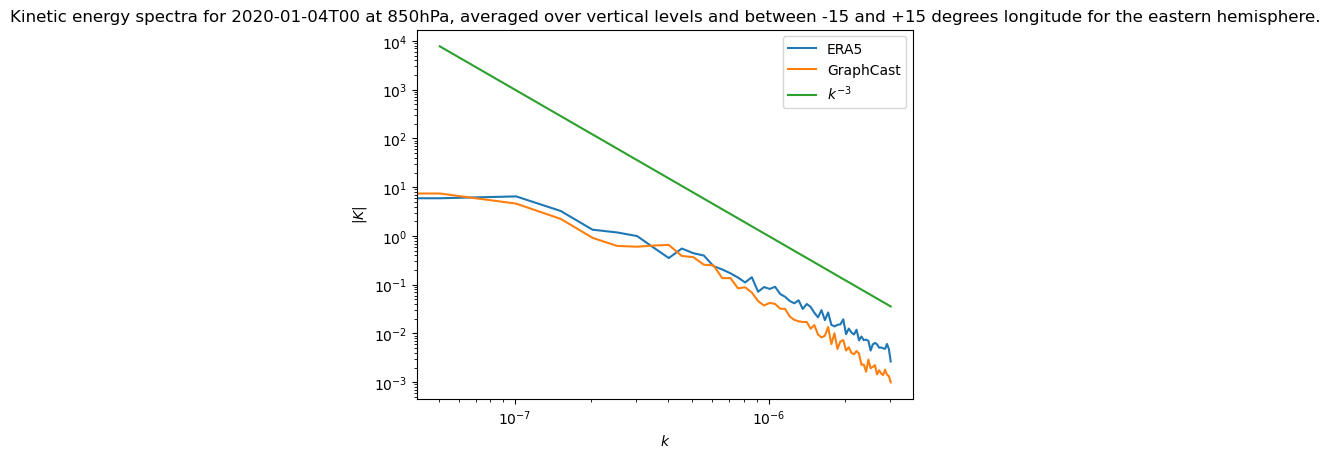

In [11]:
Khat_eq_avg = Khat.sel(time=date,level=level).mean(dim='latitude')
Khat_gc_eq_avg = Khat_gc.sel(time=date,level=level).mean(dim='latitude')
freq = Khat_eq_avg['frequency'].to_numpy()
freq_gc = Khat_gc_eq_avg['frequency'].to_numpy()
amp_sq = Khat_eq_avg['amplitude_squared'].to_numpy()
amp_sq_gc = Khat_gc_eq_avg['amplitude_squared'].to_numpy()
plt.loglog(freq,amp_sq)
plt.loglog(freq_gc,amp_sq_gc)
plt.plot(freq[1:],1.0e-18*np.power(freq[1:],-3.))
plt.title('Kinetic energy spectra for ' + date + ' at ' + str(level) + \
          'hPa, averaged over vertical levels and between -15 and +15 degrees longitude for the eastern hemisphere.')
plt.legend(['ERA5', 'GraphCast', r'$k^{-3}$'])
plt.ylabel(r'$|K|$')
plt.xlabel(r'$k$')
plt.show()

Instead of the kinetic energy, we can also compute the spectra for a custom scalar field, in this case the temperature

In [12]:
That = power_spectra_scalar(ds, reduce_vertical=False, reduce_time=False, scalar_field_name='t')
That_gc = power_spectra_scalar(ds_gc, reduce_vertical=False, reduce_time=False, scalar_field_name='t')

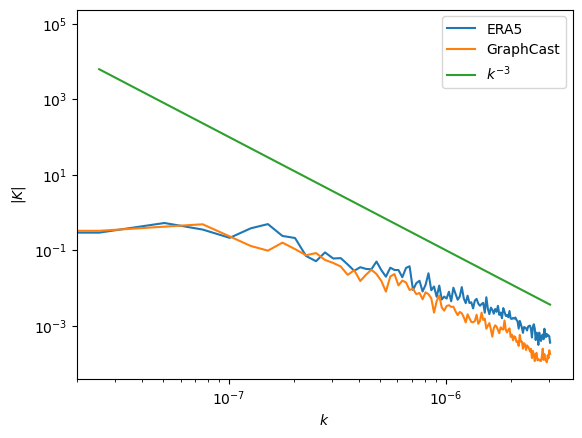

In [13]:
That_eq_avg = That.sel(latitude=lats,time=date,level=level).mean(dim='latitude')
That_gc_eq_avg = That_gc.sel(latitude=lats,time=date,level=level).mean(dim='latitude')
freq = That_eq_avg['frequency'].to_numpy()
freq_gc = That_gc_eq_avg['frequency'].to_numpy()
amp_sq = That_eq_avg['amplitude_squared'].to_numpy()
amp_sq_gc = That_gc_eq_avg['amplitude_squared'].to_numpy()
plt.loglog(freq,amp_sq)
plt.loglog(freq_gc,amp_sq_gc)
plt.plot(freq[1:],1.0e-19*np.power(freq[1:],-3.))
plt.title('Power spectra for the temperature field at' + date + ' at ' + str(level) + \
          'hPa, averaged between -15 and +15 degrees latitude.')
plt.legend(['ERA5', 'GraphCast', r'$k^{-3}$'])
plt.ylabel(r'$|K|$')
plt.xlabel(r'$k$')
plt.show()